In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)

💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 7.1 割り込み (`Concept of Interrupts`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.1_Concept_of_Interrupts.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.11%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20IDT%20%7C%20MSI-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

## 🎯 本節の目的と学習目標

第6章（`day06c`）において、私たちはついに USB 3.0 ホストコントローラ（xHCI）からマウス入力を読み取り、デスクトップ画面上でマウスカーソルを自在に動かすことに成功しました。しかし、その入力処理メカニズムは **「無限ループ内でひたすらイベントの到着を監視し続ける」というポーリング（Polling）方式** でした。

本節から始まる **第7章「割り込みとFIFO (`Interrupts and FIFO`)」** では、このポーリング方式が抱える決定的な構造的欠陥を暴き、現代のすべてのコンピュータアーキテクチャとオペレーティングシステムの中核を成す **「ハードウェア割り込み（Hardware Interrupts）」** および **「イベント駆動型制御（Event-Driven Architecture）」** の全貌を解き明かします。

### 📚 本節の重要トピック
1. **なぜ割り込みが必要なのか？**: ポーリング方式の3大欠陥（CPU資源100%浪費、応答遅延とジッター、マルチタスクとの非両立）
2. **イベント駆動制御の本質**: 周辺機器からの能動的通知、CPUの省電力アイドル（`HLT` 命令）と自動復帰（Wakeup）
3. **定量的数理モデル**: ポーリング vs 割り込み駆動の CPU 利用率、応答レイテンシ、エネルギー消費量の数学的導出
4. **x86-64 割り込み・例外の分類体系**: 外部ハードウェア割り込み、ソフトウェア割り込み、CPU例外（Fault / Trap / Abort）
5. **ハードウェアスタックフレーム (`InterruptFrame`)**: 割り込み発生時に CPU が自動退避する 5 つのレジスタ（`SS`, `RSP`, `RFLAGS`, `CS`, `RIP`）の必然性
6. **第7章ロードマップ**: 割り込みハンドラ（7.2）、IDT（7.4）、MSI（7.5）、FIFOリングバッファ（7.9）への布石

---

## 1. なぜ割り込み（Interrupt）が必要なのか？（ポーリング方式の限界）

### 1.1 第6章のポーリング実装を振り返る

第6章のメインループ（`kernel/main.cpp`）は以下のようなコードでした：

```cpp
while (1) {
    if (auto err = xhc.ProcessEvent()) {
        Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
            err.Name(), err.File(), err.Line());
    }
}
```

このコードでは、CPU は **1秒間に数十億回** のペースで `xhc.ProcessEvent()` を呼び出し続けます。マウスが動いていない静止時であっても、CPU は休むことなく Event Ring の TRB を確認しては「何もイベントがない」という結果を返すだけの空回りを続けます。

```text
【第6章のポーリング方式 (Polling / Busy-Wait)】
  CPU 実行状態: 常に 100% 全開 (Busy-Wait Loop)
  
       ┌────────────────────────┐
  ┌───>│ xhc.ProcessEvent() 実行│
  │    └───────────┬────────────┘
  │                ▼
  │         イベントあるか？
  │          ／          ＼
  │     (Yes)             (No: 99.999%の時間はこっち)
  │        ▼               │
  │    マウス移動          │
  │    カーソル再描画      │
  │        │               │
  └────────┴───────────────┘
```

### 1.2 ポーリング方式が抱える「3大構造的欠陥」

| 欠陥項目 | 発生メカニズムと現実の影響 | 深刻度 |
|---|---|:---:|
| **① CPU資源100%浪費と発熱・電力消費** | イベントがないアイドル時でも CPU コアが最高周波数でフル回転し続けるため、ファンが轟音を立てて回り、ノートPCのバッテリーは瞬く間に枯渇します。省電力モードに移行できません。 | 致命的 |
| **② 応答遅延（レイテンシ）の増大とジッター** | もしメインループ内で重い処理（画面全体の大規模描画、ファイルI/O、複雑な計算など）が実行されると、ポーリングの間隔が数十〜数百ミリ秒に延びてしまいます。その結果、マウス操作が引っかかる「カクつき（Jitter）」やイベントの取りこぼしが発生します。 | 重大 |
| **③ マルチタスク OS との非両立** | 将来的に複数のアプリケーションやバックグラウンドタスクを並行動作させる際、1つのタスクがビジーループで CPU を独占してしまうと、他のタスクに計算時間を割り当てられなくなります。 | 構造的破綻 |

---

## 2. ハードウェア割り込みの基本概念とイベント駆動制御

### 2.1 割り込み（Interrupt）とは何か？

「**割り込み（*Interrupt*）**」とは、CPU の通常処理の流れをハードウェア的に一時停止させ、あらかじめ登録された専用の処理ルーチン（**割り込みハンドラ / *ISR: Interrupt Service Routine***）へ強制的に分岐させる仕組みです。

ポーリングが「**店員が1秒ごとにお客さんが来たかどうかドアを見に行く**」アプローチだとすれば、割り込みは「**ドアチャイム（呼び鈴）が鳴ったときだけ店員が顔を上げる**」アプローチです。

```text
【割り込み駆動アプローチ (Interrupt-Driven Architecture)】

  [ 通常のCPU処理 / または HLT スリープ状態 ]
           │
           │  (CPUは他の計算を実行、または省電力待機中)
           │
           ├──────────────────────────────┐
           │ ★ ハードウェア割り込み発生！  │ (xHCI マウスパケット受信)
           ▼                              ▼
  [ 実行状態の自動退避 ]          [ 割り込みハンドラ (ISR) ]
  (RIP, CS, RFLAGS, RSP, SS)      • Event Ring からパケット取得
           │                      • マウス座標更新
           │                      • レイヤ再描画
           │                              │
           │ <────── IRETQ (復帰) ────────┘
           ▼
  [ 元の処理を再開 ]
```

### 2.2 CPU省電力命令 `HLT` による真のアイドル状態

x86-64 CPU には、プロセッサを休止状態にする特権命令 **`HLT` (*Halt*)** が備わっています。

`HLT` 命令が実行されると、CPU は内部クロックの供給を停止（*Clock Gating*）し、外部からの割り込み信号（*Interrupt Request: IRQ*）を受信するまで、極小の消費電力で完全な停止待機状態（C1ステート）に入ります。

割り込みが届いた瞬間に、ハードウェアが自動的に CPU を起床（*Wakeup*）させ、割り込みハンドラを実行します。これにより、**「何もないときは電力を一切消費せず、何か起きた瞬間だけマイクロ秒単位で即座に応答する」** という理想的なイベント駆動アーキテクチャが実現します。

---

## 3. ポーリング vs 割り込み駆動の定量的数理モデル

ポーリングと割り込み駆動の決定的な違いを、数理モデルによって定量的に導出してみましょう。

### 3.1 応答レイテンシ（Latency）の数理モデル

今、メインループの1周期にかかる時間を $T_{loop}$、イベントの発生時刻を確率変数 $t \sim U(0, T_{loop})$（一様分布）とします。

- **ポーリング方式の期待レイテンシ**:
  $$\mathbb{E}[L_{poll}] = \int_{0}^{T_{loop}} (T_{loop} - t) \cdot \frac{1}{T_{loop}} \, dt = \frac{T_{loop}}{2}$$
  最大レイテンシは $L_{max} = T_{loop}$ となり、ループ周期に直接比例します。もしループ内に $100\text{ms}$ の重い描画処理が存在すれば、最大遅延は $100\text{ms}$、平均遅延も $50\text{ms}$ にまで悪化します。

- **割り込み駆動方式の期待レイテンシ**:
  $$L_{intr} = t_{prop} + t_{apic} + t_{cpu\_switch} \approx 1 \sim 5\, \mu\text{s}$$
  ハードウェア電気信号の伝播時間と CPU のスタック退避時間のみに依存するため、メインループの負荷状況に関係なく **常に数マイクロ秒の極小かつ一定の遅延** に抑えられます。

### 3.2 CPU 利用率（CPU Utilization）の数理モデル

観測時間を $T$、時間内に発生したイベント数を $N$、1回のイベント処理にかかる時間を $t_{handler}$ とします。

- **ポーリング方式の CPU 利用率**:
  $$U_{poll} = \frac{T_{busy}}{T} = 100\%$$
  イベントの有無にかかわらず常に CPU がビジー回転するため、利用率は常に $100\%$ です。

- **割り込み駆動方式（HLT 待機併用）の CPU 利用率**:
  $$U_{intr} = \frac{N \cdot t_{handler}}{T} \times 100\%$$
  例えば、USB マウスのレポートレートが $100\text{Hz}$（1秒間に100回）、ハンドラ実行時間が $25\,\mu\text{s}$ の場合：
  $$U_{intr} = \frac{100 \times 25 \times 10^{-6}\text{s}}{1.0\text{s}} \times 100\% = 0.25\%$$
  CPU は **$99.75\%$ の時間を省電力スリープ** に充てることができ、消費電力と発熱は激減します。

✅ Figure 7.01 を生成・保存しました: 7/result/fig7_01_polling_vs_interrupt_timeline.png

【シミュレーション測定メトリクス比較 (100ms 区間・イベント5回)】
• ポーリング方式   : 平均遅延 =   6.20 ms | 最大遅延 =   9.00 ms | CPU負荷 = 100.0% | 消費エネルギー = 6.50 J
• 割り込み駆動方式 : 平均遅延 =  0.005 ms | 最大遅延 =  0.005 ms | CPU負荷 =  0.12% | 消費エネルギー = 0.51 J
★ レイテンシ改善率 : 約 1240 倍の高速化！
★ CPU 負荷削減率   : 99.88% の CPU リソースを解放！


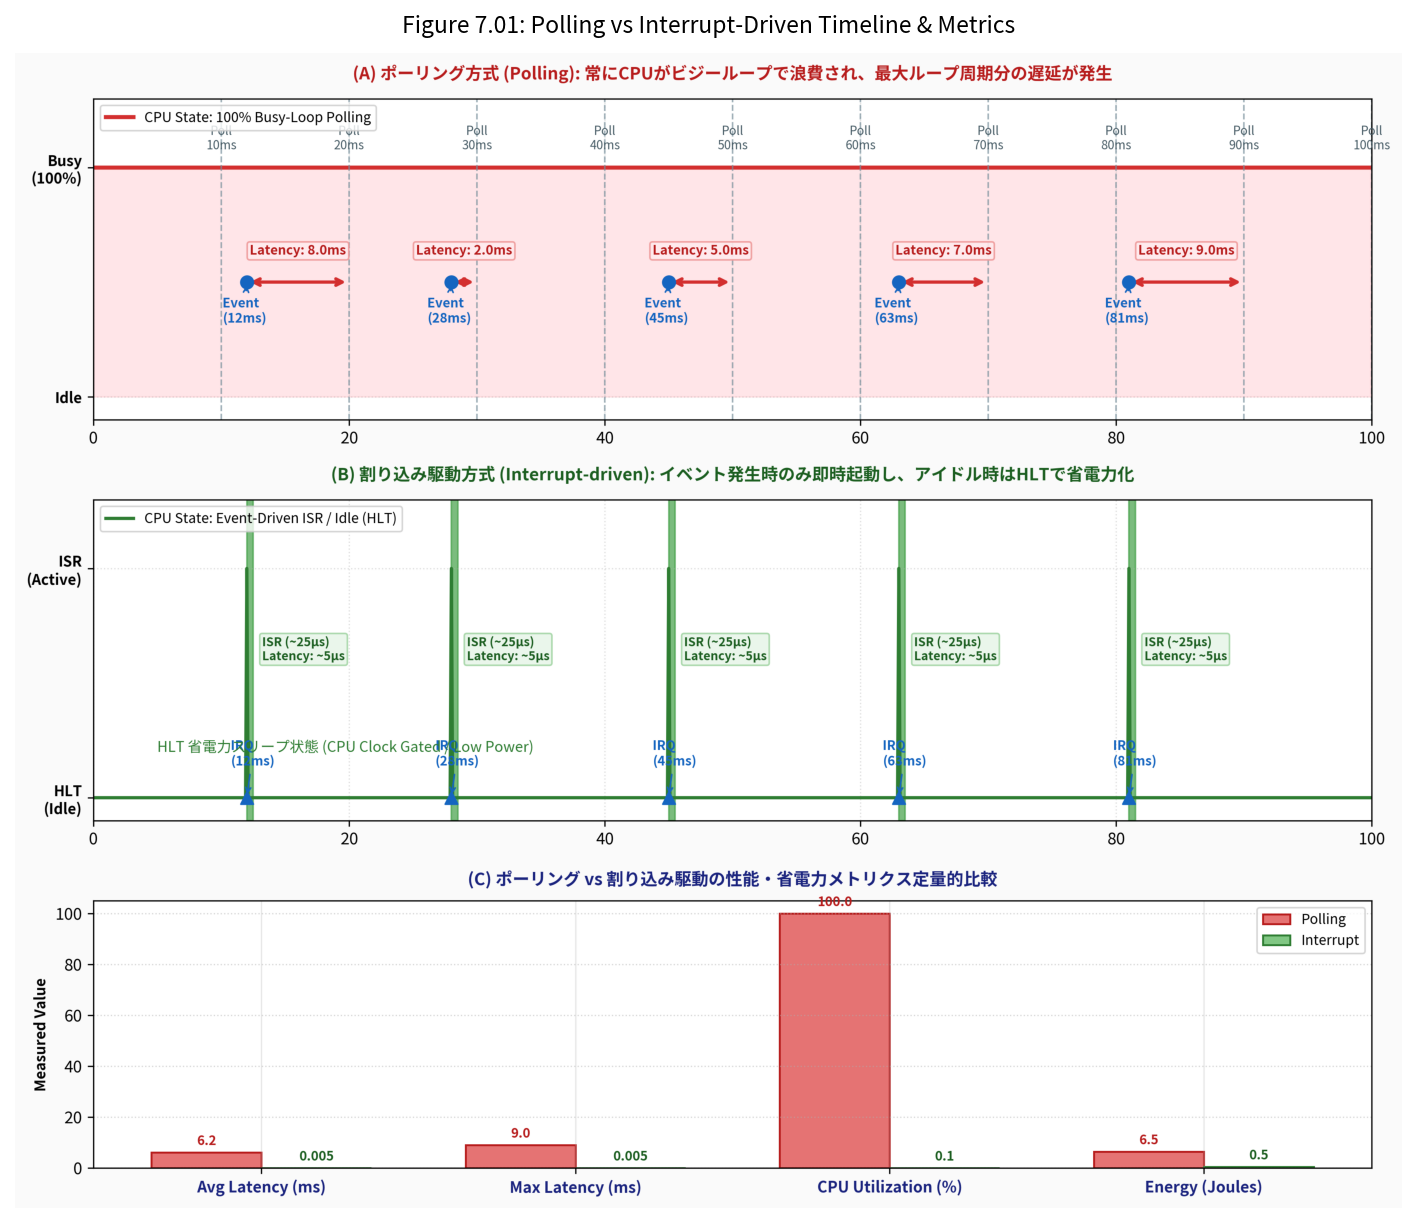

In [2]:
# === Figure 7.01: ポーリング vs 割り込み駆動のタイミングチャート & メトリクス比較 ===
import matplotlib.pyplot as plt
import numpy as np
from common import (
    PollingVsInterruptBenchmarker,
    plot_fig7_01_polling_vs_interrupt_timeline,
)

# 1. 高解像度プロット生成
fig_path = plot_fig7_01_polling_vs_interrupt_timeline("7/result/fig7_01_polling_vs_interrupt_timeline.png")
print(f"✅ Figure 7.01 を生成・保存しました: {fig_path}")

# 2. 定量ベンチマークの実行と数値確認
benchmarker = PollingVsInterruptBenchmarker(
    loop_interval_ms=10.0,
    task_workload_ms=8.0,
    handler_execution_us=25.0,
    cpu_idle_power_w=5.0,
    cpu_active_power_w=65.0,
)
events = [12.0, 28.0, 45.0, 63.0, 81.0]
pol_res, int_res = benchmarker.run_simulation(total_time_ms=100.0, event_times_ms=events)

print("\n【シミュレーション測定メトリクス比較 (100ms 区間・イベント5回)】")
print(f"• ポーリング方式   : 平均遅延 = {pol_res.avg_latency_ms:6.2f} ms | 最大遅延 = {pol_res.max_latency_ms:6.2f} ms | CPU負荷 = {pol_res.cpu_utilization_pct:5.1f}% | 消費エネルギー = {pol_res.energy_consumed_joules:.2f} J")
print(f"• 割り込み駆動方式 : 平均遅延 = {int_res.avg_latency_ms:6.3f} ms | 最大遅延 = {int_res.max_latency_ms:6.3f} ms | CPU負荷 = {int_res.cpu_utilization_pct:5.2f}% | 消費エネルギー = {int_res.energy_consumed_joules:.2f} J")
print(f"★ レイテンシ改善率 : 約 {pol_res.avg_latency_ms / int_res.avg_latency_ms:.0f} 倍の高速化！")
print(f"★ CPU 負荷削減率   : {100.0 - int_res.cpu_utilization_pct:.2f}% の CPU リソースを解放！")

# 3. 生成された図版を表示
img = plt.imread(fig_path)
plt.figure(figsize=(12, 10), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 7.01: Polling vs Interrupt-Driven Timeline & Metrics", fontsize=11, pad=10)
plt.show()

---

## 4. x86-64 アーキテクチャにおける割り込み・例外の分類体系

x86-64 プロセッサにおいて、通常の実行フローを中断させるイベントは、その発生要因と同期性に応じて **大きく3つのカテゴリ** に体系化されています。

```text
                         x86-64 割り込み・例外体系
                                    │
       ┌────────────────────────────┼────────────────────────────┐
       ▼                            ▼                            ▼
① 外部ハードウェア割り込み     ② ソフトウェア割り込み          ③ CPU 例外
  (Hardware IRQ / MSI)         (Software Interrupt)          (CPU Exceptions)
       │                            │                            │
  • 非同期 (Asynchronous)      • 同期 (Synchronous)         ┌────┼────┐
  • タイマ, xHCI, キーボード   • INT n 命令, SYSCALL        ▼    ▼    ▼
  • IF フラグでマスク可能      • ユーザー→カーネル遷移     Fault Trap Abort
```

### 4.1 3大分類の定義と特徴

1. **外部ハードウェア割り込み (*External Hardware Interrupts*)**:
   - **同期性**: **非同期（*Asynchronous*）**。CPU の命令実行とは完全に独立したタイミングで、外部ハードウェア（USB xHCI、タイマ、キーボードなど）から電気信号（または MSI パケット）として届きます。
   - **マスク制御**: `RFLAGS` レジスタの `IF` (*Interrupt Flag*) ビットが `1` のときのみ受付（`STI` 命令）。`0` のときは保留（`CLI` 命令）。※NMI（マスク不能割り込み）を除く。
2. **ソフトウェア割り込み (*Software Interrupts*)**:
   - **同期性**: **同期（*Synchronous*）**。CPU が特定の機械語命令（`INT n`、`INT3`、`INTO` 等）を実行した瞬間に能動的に発生します。
   - **用途**: レガシー BIOS API 呼び出し、デバッガのブレークポイント、レガシー OS のシステムコール。
3. **CPU 例外 (*CPU Exceptions*)**:
   - CPU が命令を実行した結果、異常や特別な条件を検知した際にハードウェアが自動発生させる内部割り込みです。挙動に応じてさらに3種類に分類されます：

| 例外タイプ | 発生タイミングと復帰動作 | 代表例 |
|---|---|---|
| **フォールト (*Fault*)** | 命令実行の **直前（実行前）** に検出。原因を解決した後、**同じ命令を再実行** する。 | ページフォルト（`#PF` 14番：デマンドページング）、一般保護例外（`#GP` 13番） |
| **トラップ (*Trap*)** | 命令実行の **完了直後** に検出。**次の命令** から実行を継続する。 | デバッグ例外（`#DB` 1番）、ブレークポイント（`#BP` 3番） |
| **アボート (*Abort*)** | ハードウェア障害や二重障害など、処理の継続が不可能な致命的エラー。**復帰不能**。 | ダブルフォルト（`#DF` 8番）、マシンチェック例外（`#MC` 18番） |

### 4.2 x86-64 割り込みベクタ番号（0〜255）の割り当て設計

x86-64 では、割り込みの種類を **0〜255 の 8ビット整数（割り込みベクタ番号 / *Vector Number*）** で識別します。

```text
  ベクタ番号 0                        31 32                                      255
  ┌───────────────────────────────────┬───────────────────────────────────────────┐
  │      Intel CPU 予約例外領域       │       OS / ユーザー定義割り込み領域       │
  │  (0: #DE, 8: #DF, 13: #GP, 14: #PF) │ (32〜255: タイマ, xHCI, キーボード, 等)   │
  └───────────────────────────────────┴───────────────────────────────────────────┘
```

- **0〜31（予約領域）**: Intel アーキテクチャにより固定された CPU 例外領域。OS 側が自由に変更することはできません。
- **32〜255（ユーザー定義領域）**: OS 開発者が自由に周辺機器やタイマに割り当て可能な領域。MikanOS では、次節以降で xHCI の MSI 割り込みをベクタ番号 `0x40`（64番）などに割り当てていきます。

---

## 5. 割り込み発生時の CPU 自動スタック退避機構と `InterruptFrame`

### 5.1 通常の関数呼び出し（`CALL`）との決定的相違

C/C++ の通常の関数呼び出し（`call foo`）では、CPU は「戻り先アドレス（`RIP`）」の 8 バイトのみをスタックに積みます。

しかし、割り込みは **「CPU が今まさに何をやっている最中か全く分からないタイミングで突然発生する」** ため、`RIP` だけでは元の状態に復元できません。

そのため、x86-64 CPU は割り込みを受信した瞬間、**以下の 5 つのレジスタ（合計 40 バイト）をハードウェアが完全に自動でスタックにプッシュ** します。

```text
  高位アドレス (スタック底方向)
  ┌──────────────────────────────────────────────┐
  │ [RSP + 32]  SS      (スタックセグメントセレクタ)│
  ├──────────────────────────────────────────────┤
  │ [RSP + 24]  RSP     (割り込み直前のスタックポインタ) │
  ├──────────────────────────────────────────────┤
  │ [RSP + 16]  RFLAGS  (フラグ: IF, IOPL, ゼロフラグ等) │
  ├──────────────────────────────────────────────┤
  │ [RSP +  8]  CS      (コードセグメントセレクタ) │
  ├──────────────────────────────────────────────┤
  │ [RSP +  0]  RIP     (復帰先命令ポインタ)     │ <── ハンドラ突入時の新 RSP
  └──────────────────────────────────────────────┘
  低位アドレス (スタック先頭方向)
```

> [!IMPORTANT]
> **なぜ `RSP` と `SS` まで自動退避されるのか？**:
> 将来、CPU がユーザーモード（Ring 3）で動作している最中に割り込みが発生した場合、CPU はスタックをカーネルスタック（Ring 0）へ切り替える必要があります。その際、ユーザー側のスタック位置（`RSP`/`SS`）を保存しておかなければユーザー空間に戻れなくなるため、x86-64 Long Mode では常に `RSP` と `SS` をスタックに保存する仕様になっています。

### 5.2 復帰命令 `IRETQ`

割り込みハンドラの処理が完了した際、通常の関数リターン命令 `RET`（`RIP` のみをポップ）を使ってはいけません。

必ず 64 ビット割り込み復帰専用命令 **`IRETQ` (*Interrupt Return 64-bit*)** を実行します。`IRETQ` 命令は、スタックから `RIP`, `CS`, `RFLAGS`, `RSP`, `SS` を一挙にアトミックに復元し、割り込みが発生した直前の CPU 状態へ何事もなかったかのように復帰させます。

✅ Figure 7.02 を生成・保存しました: 7/result/fig7_02_interrupt_classification_and_lifecycle.png


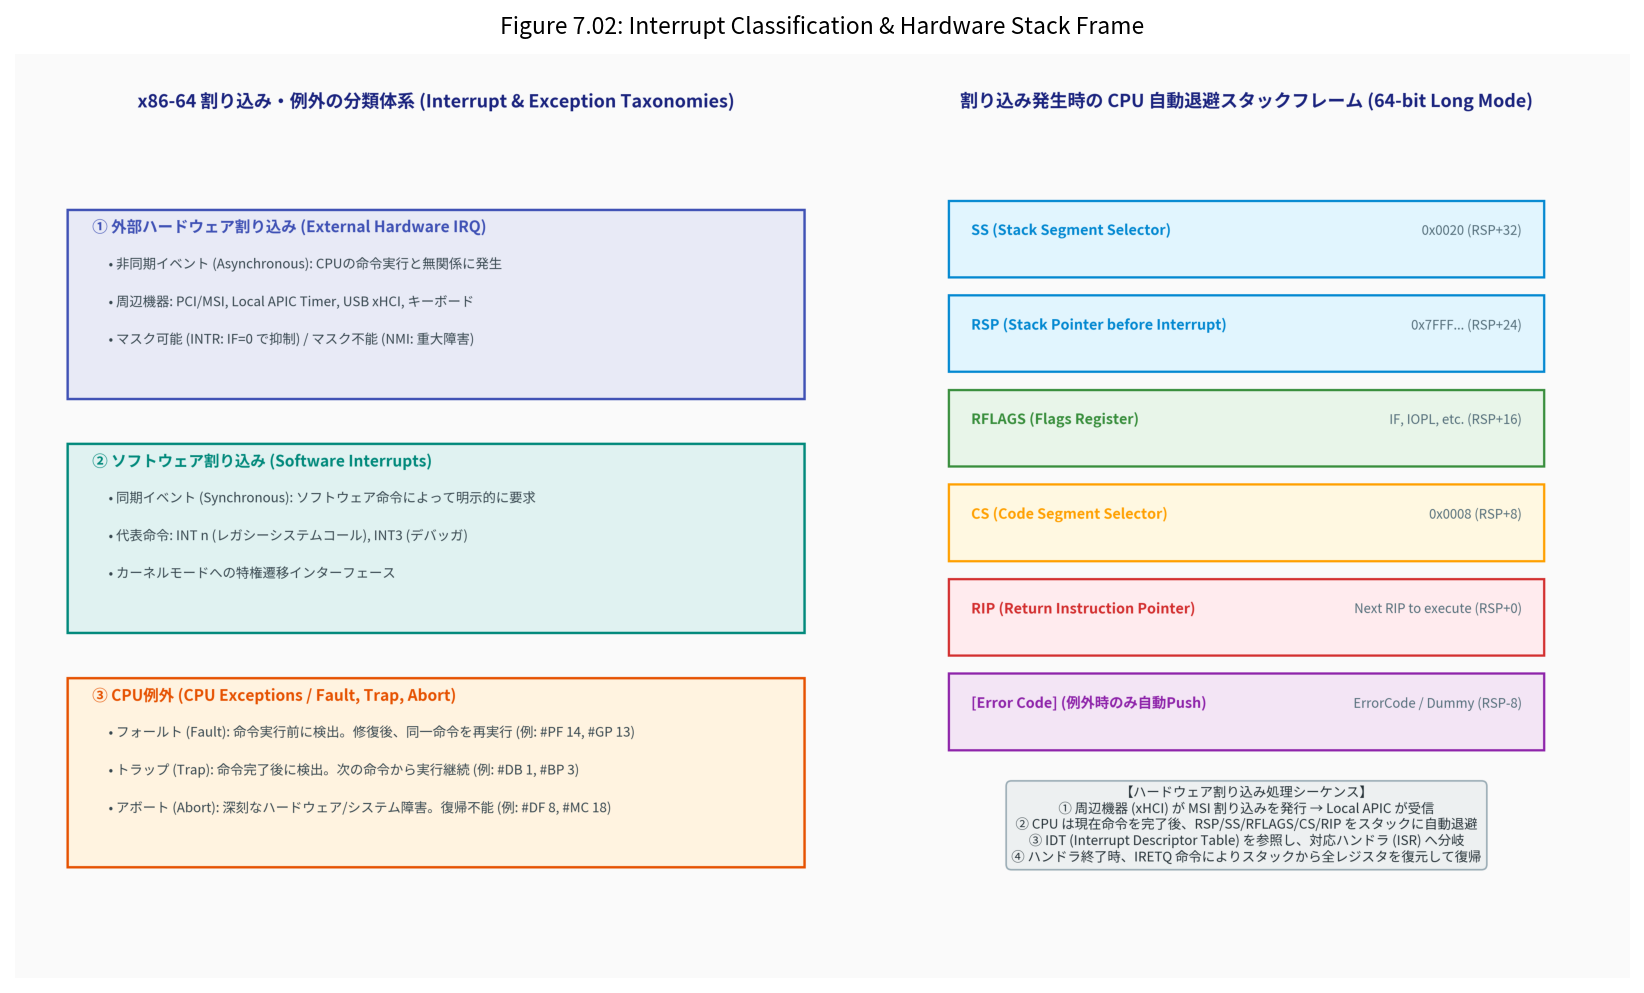

In [3]:
# === Figure 7.02: 割り込み分類体系 & スタックフレーム構造 ===
from common import plot_fig7_02_interrupt_classification_and_lifecycle

fig2_path = plot_fig7_02_interrupt_classification_and_lifecycle("7/result/fig7_02_interrupt_classification_and_lifecycle.png")
print(f"✅ Figure 7.02 を生成・保存しました: {fig2_path}")

img2 = plt.imread(fig2_path)
plt.figure(figsize=(14, 8), dpi=150)
plt.imshow(img2)
plt.axis("off")
plt.title("Figure 7.02: Interrupt Classification & Hardware Stack Frame", fontsize=11, pad=10)
plt.show()

---

## 6. MikanOS 第7章の全体ロードマップ

第7章「割り込みとFIFO」は、全10節にわたって MikanOS を本格的なイベント駆動 OS へと進化させる極めて重要な章です。全体のステップを確認しておきましょう：

```mermaid
flowchart TD
    S1["7.1 割り込みの概念 (本節)
ポーリングの限界とイベント駆動・HLTの優位性"] --> S2["7.2 割り込みハンドラ
__attribute__((interrupt)) と IRETQ"]
    S2 --> S3["7.3 割り込みベクタ設計
例外 (0-31) と OS ベクタ (32-255) の割り当て"]
    S3 --> S4["7.4 割り込み記述子の設定
16バイト IDT エントリ構築と LIDT 命令"]
    S4 --> S5["7.5 MSI 割り込み
PCI Configuration 空間と Local APIC 連携"]
    S5 --> S6["7.6 割り込みのまとめ
マウス移動からハンドラ起動までの結合トレース"]
    S6 --> S7["7.7 ハンドラの高速化
Top-half / Bottom-half 分離の必要性"]
    S7 --> S8["7.8 FIFO と FILO
キューによる順序保証データ構造"]
    S8 --> S9["7.9 キューの実装
リングバッファ ArrayQueue の構築"]
    S9 --> S10["7.10 キューを使ったイベントループ
CLI / STI / HLT による完全なイベント駆動化"]
```

次節（7.2節）では、C++ コンパイラが割り込み関数を生成するための特殊属性 `__attribute__((interrupt))` とスタックアライメントの秘密に迫ります。

---

## 7. C++20 による割り込みコアデータ構造のスタンドアロン検証

ホスト環境（Linux / Colab）上で、x86-64 ハードウェアが規定する `InterruptFrame` のメモリサイズ（40バイト）およびメンバオフセット、ならびにポーリング vs 割り込み駆動の性能差を C++20 で厳密に検証します。

検証コードは [`src/ch07/interrupt_concept_sim.cpp`](../src/ch07/interrupt_concept_sim.cpp) に配備されています。

In [4]:
# === C++20 検証コードのコンパイルと実行 ===
import subprocess

cpp_source = "src/ch07/interrupt_concept_sim.cpp"
bin_target = "src/ch07/interrupt_concept_sim"

# 1. コンパイル実行 (-std=c++20 -O2 -Wall -Wextra)
compile_cmd = f"g++ -std=c++20 -O2 -Wall -Wextra -pedantic {cpp_source} -o {bin_target}"
res = subprocess.run(compile_cmd, shell=True, capture_output=True, text=True)
if res.returncode != 0:
    print("❌ コンパイルエラー:")
    print(res.stderr)
else:
    print("✅ C++20 バイナリのコンパイルに成功しました。")

# 2. バイナリの実行
run_res = subprocess.run(f"./{bin_target}", shell=True, capture_output=True, text=True)
print(run_res.stdout)
if run_res.stderr:
    print("Stderr:", run_res.stderr)

✅ C++20 バイナリのコンパイルに成功しました。
🍊 MikanOS Chapter 7.1: Concept of Interrupts Verification Suite

[Part 1] Verifying x86-64 InterruptFrame memory layout...
  ✓ sizeof(InterruptFrame) = 40 bytes (5 registers x 8B)
  ✓ sizeof(InterruptFrameWithError) = 48 bytes
  ✓ Register offsets: RIP=0, CS=8, RFLAGS=16, RSP=24, SS=32 (Verified)

[Part 2] Simulating Hardware Push of InterruptFrame...
  Pushed Stack Frame (top-down as CPU pushes):
    [RSP+32] SS:     0x0000000000000010
    [RSP+24] RSP:    0x00007fffffffe000
    [RSP+16] RFLAGS: 0x0000000000000202 (IF=1)
    [RSP+ 8] CS:     0x0000000000000008
    [RSP+ 0] RIP:    0x00000000001045a0 (Return Addr)
  ✓ InterruptFrame structure dump verified.

[Part 3] Running Quantitative Benchmark: Polling vs Interrupt-Driven...
  +--------------------------------+-----------------+-----------------+
  | Metric                         | Polling Mode    | Interrupt Mode  |
  +--------------------------------+-----------------+-----------------+
  | Events Proc

---

## 8. 理解度チェック & まとめ

### 8.1 3問セルフチェッククイズ

**Q1: ポーリング方式と比較した割り込み駆動方式の最大のメリットは何ですか？**
> **A1**: イベントが発生していないアイドル時に CPU が `HLT` 命令でクロックを停止（省電力スリープ）でき、イベント発生時はメインループの負荷状況に関係なく数マイクロ秒の即時応答（低レイテンシ）が得られる点です。

**Q2: x86-64 で割り込みが発生した際、CPU ハードウェアがスタックに自動退避する 5 つのレジスタは何ですか？**
> **A2**: 高位アドレス側から順に `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` です（合計 40 バイト）。

**Q3: 通常の関数リターン命令 `RET` と割り込み復帰命令 `IRETQ` の違いは何ですか？**
> **A3**: `RET` 命令はスタックから `RIP`（8バイト）のみを復元しますが、`IRETQ` 命令は `RIP`, `CS`, `RFLAGS`, `RSP`, `SS` の 5 レジスタ（40バイト）すべてをアトミックにスタックから復元して割り込み前の状態に復帰します。

---

## 🏆 本節のまとめ

1. **ポーリングの限界**: 第6章の `while(1) { ProcessEvent(); }` は CPU 負荷 100% を強要し、メインループの重い処理でマウスがカクつく構造的欠陥を抱えていた。
2. **割り込みの本質**: 周辺機器から能動的に CPU へ通知し、CPU はアイドル時に `HLT` でスリープ待機するイベント駆動制御を実現する。
3. **スタックフレーム**: x86-64 は割り込み時に `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` の 5 レジスタ（40バイト）を自動退避し、ハンドラは `IRETQ` 命令で復帰する。
4. **分類体系**: 外部ハードウェア割り込み（非同期）、ソフトウェア割り込み（同期）、CPU例外（Fault / Trap / Abort）の3大分類とベクタ番号（0〜255）の役割を理解した。

次節 **第7.2節「割り込みハンドラ」** では、実際にコンパイラが割り込み関数を生成するための `__attribute__((interrupt))` 属性の仕組みを深く掘り下げます！